In [4]:
# Usual Libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Librosa (the mother of audio files)
import librosa
import warnings
warnings.filterwarnings('ignore')

In [5]:
import sklearn
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import scale, minmax_scale, LabelEncoder
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier, XGBRFClassifier

In [6]:
import os
general_path = '../BongcayaoTanalgo_ISCS30.63'
print(list(os.listdir(f'{general_path}')))

['.git', '.gitignore', 'beethoven.wav', 'best_model.ckpt', 'conf matrix.png', 'confmatrix_model4-FINAL.png', 'extracted-features', 'genres', 'gtzanvenv', 'orchestra.wav', 'project-ver2.ipynb', 'project.ipynb', 'requirements.txt', 'test_filtered.txt', 'traininghistory-model4-FINAL.png', 'train_filtered.txt', 'valid_filtered.txt']


# making dataframe

In [39]:
GTZAN_GENRES = ['blues', 'classical', 'country', 'disco', 'hiphop', 'jazz', 'metal', 'pop', 'reggae', 'rock']

In [ ]:
rows = []

for genre in GTZAN_GENRES:
    for i in range(100):
        if genre == "jazz" and i==54:
            continue
        number = "0000" + str(i) if i<10 else "000" + str(i)

        path = f'{genre}/{genre}.{number}.wav'
        
        y, sr = librosa.load(f'genres/{path}')

        audio_file, _ = librosa.effects.trim(y)

        zero_crossing_rate = librosa.feature.zero_crossing_rate(audio_file, pad=False)
        mean_zero_crossing_rate = np.mean(zero_crossing_rate)
        var_zero_crossings_rate = np.var(zero_crossing_rate)

        chroma_stft = librosa.feature.chroma_stft(y=audio_file,sr=sr)
        mean_chroma_stft = np.mean(chroma_stft)
        var_chroma_stft = np.var(chroma_stft)

        rms = librosa.feature.rms(y=audio_file)
        mean_rms = np.mean(rms)
        var_rms = np.var(rms)

        spectral_centroid = librosa.feature.spectral_centroid(y=audio_file, sr=sr)
        mean_spectral_centroid = np.mean(spectral_centroid)
        var_spectral_centroid = np.var(spectral_centroid)

        spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio_file, sr=sr)
        mean_spectral_bandwidth = np.mean(spectral_bandwidth)
        var_spectral_bandwidth = np.var(spectral_bandwidth)

        spectral_rolloff = librosa.feature.spectral_rolloff(y=audio_file, sr=sr)
        mean_spectral_rolloff = np.mean(spectral_rolloff)
        var_spectral_rolloff = np.var(spectral_rolloff)

        harmonic, percussive = librosa.effects.hpss(audio_file)
        mean_harmonic = np.mean(harmonic)
        var_harmonic = np.var(harmonic)
        mean_percussive = np.mean(percussive)
        var_percussive = np.var(percussive)

        tempo = librosa.feature.tempo(y=audio_file, sr=sr)

        mfccs = librosa.feature.mfcc(y=audio_file, sr=sr)
        mfcc_means = np.mean(mfccs, axis=1)
        mfcc_vars = np.var(mfccs, axis=1)
        
        rows.append({
            'path': path,
            'length': (np.shape(y))[0],
            'sample_rate': sr,
            'chroma_stft_mean': mean_chroma_stft,
            'chroma_stft_var': var_chroma_stft,
            'rms_mean': mean_rms,
            'rms_var': var_rms,
            'spectral_centroid_mean': mean_spectral_centroid,
            'spectral_centroid_var': var_spectral_centroid,
            'spectral_bandwidth_mean': mean_spectral_bandwidth,
            'spectral_bandwidth_var': var_spectral_bandwidth,
            'spectral_rolloff_mean': mean_spectral_rolloff,
            'spectral_rolloff_var': var_spectral_rolloff,
            'zero_crossing_rate_mean': mean_zero_crossing_rate,
            'zero_crossing_rate_var': var_zero_crossings_rate,
            'harmony_mean': mean_harmonic,
            'harmony_var': var_harmonic,
            'percussive_mean': mean_percussive,
            'percussive_var': var_percussive,
            'tempo': tempo[0],
            'mfcc1_mean':mfcc_means[0],
            'mfcc1_var':mfcc_vars[0],
            'mfcc2_mean':mfcc_means[1],
            'mfcc2_var':mfcc_vars[1],
            'mfcc3_mean':mfcc_means[2],
            'mfcc3_var':mfcc_vars[2],
            'mfcc4_mean':mfcc_means[3],
            'mfcc4_var':mfcc_vars[3],
            'mfcc5_mean':mfcc_means[4],
            'mfcc5_var':mfcc_vars[4],
            'mfcc6_mean':mfcc_means[5],
            'mfcc6_var':mfcc_vars[5],
            'mfcc7_mean':mfcc_means[6],
            'mfcc7_var':mfcc_vars[6],
            'mfcc8_mean':mfcc_means[7],
            'mfcc8_var':mfcc_vars[7],
            'mfcc9_mean':mfcc_means[8],
            'mfcc9_var':mfcc_vars[8],
            'mfcc10_mean':mfcc_means[9],
            'mfcc10_var':mfcc_vars[9],
            'mfcc11_mean':mfcc_means[10],
            'mfcc11_var':mfcc_vars[10],
            'mfcc12_mean':mfcc_means[11],
            'mfcc12_var':mfcc_vars[11],
            'mfcc13_mean':mfcc_means[12],
            'mfcc13_var':mfcc_vars[12],
            'mfcc14_mean':mfcc_means[13],
            'mfcc14_var':mfcc_vars[13],
            'mfcc15_mean':mfcc_means[14],
            'mfcc15_var':mfcc_vars[14],
            'mfcc16_mean':mfcc_means[15],
            'mfcc16_var':mfcc_vars[15],
            'mfcc17_mean':mfcc_means[16],
            'mfcc17_var':mfcc_vars[16],
            'mfcc18_mean':mfcc_means[17],
            'mfcc18_var':mfcc_vars[17],
            'mfcc19_mean':mfcc_means[18],
            'mfcc19_var':mfcc_vars[18],
            'mfcc20_mean':mfcc_means[19],
            'mfcc20_var':mfcc_vars[19],
            'label': genre
        })

features_df = pd.DataFrame(rows)
features_df.head()


In [ ]:
features_df.to_csv('extracted-features/features.csv', index=False)

### Model Training

Ref: https://www.kaggle.com/code/imsparsh/gtzan-genre-classification-deep-learning-val-92-4

In [7]:
import sklearn.model_selection as skms
import sklearn.preprocessing as skp

In [8]:
seed = 12
np.random.seed(seed)

In [9]:
df = pd.read_csv(f'{general_path}/extracted-features/features.csv')
df.head()

,path,length,sample_rate,chroma_stft_mean,chroma_stft_var,rms_mean,rms_var,spectral_centroid_mean,spectral_centroid_var,spectral_bandwidth_mean,...,mfcc16_var,mfcc17_mean,mfcc17_var,mfcc18_mean,mfcc18_var,mfcc19_mean,mfcc19_var,mfcc20_mean,mfcc20_var,label
0,blues/blues.00000.wav,661794,22050,0.350129,0.088772,0.130184,0.002828,1784.1226,129745.50,2002.4126,...,52.424534,-1.687854,36.535866,-0.408730,41.603172,-2.302677,55.053654,1.222467,46.941350,blues
1,blues/blues.00001.wav,661794,22050,0.340849,0.094976,0.095908,0.002373,1530.2618,375915.50,2038.9877,...,55.337963,-0.728403,60.231407,0.296872,48.133217,-0.282430,51.106014,0.530645,45.788700,blues
2,blues/blues.00002.wav,661794,22050,0.363538,0.085257,0.175473,0.002751,1552.8325,156471.00,1747.7540,...,40.641678,-7.724840,47.629646,-1.819024,52.393597,-3.440458,46.643400,-2.238128,30.653150,blues
3,blues/blues.00003.wav,661794,22050,0.404854,0.093999,0.141040,0.006348,1070.1533,184366.02,1596.4226,...,44.432903,-3.324069,50.218452,0.636311,37.325726,-0.615968,37.257774,-3.405046,31.965254,blues
4,blues/blues.00004.wav,661794,22050,0.308526,0.087843,0.091501,0.002305,1835.1285,343249.47,1748.4106,...,85.995190,-5.451786,75.276740,-0.915952,53.633236,-4.408018,62.882492,-11.704385,55.190254,blues


In [10]:
print("Dataset has",df.shape)
print("Count of Positive and Negative samples")
df.label.value_counts().reset_index()

Dataset has (999, 61)
Count of Positive and Negative samples


,label,count
0,blues,100
1,classical,100
2,country,100
3,disco,100
4,hiphop,100
5,metal,100
6,pop,100
7,reggae,100
8,rock,100
9,jazz,99


In [11]:
# map labels to index
label_index = dict()
index_label = dict()
for i, x in enumerate(df.label.unique()):
    label_index[x] = i
    index_label[i] = x
print(label_index)
print(index_label)

{'blues': 0, 'classical': 1, 'country': 2, 'disco': 3, 'hiphop': 4, 'jazz': 5, 'metal': 6, 'pop': 7, 'reggae': 8, 'rock': 9}
{0: 'blues', 1: 'classical', 2: 'country', 3: 'disco', 4: 'hiphop', 5: 'jazz', 6: 'metal', 7: 'pop', 8: 'reggae', 9: 'rock'}


In [12]:
seed = 42

# shuffle samples
df_shuffle = df.sample(frac=1, random_state=seed).reset_index(drop=True)

In [13]:
# remove irrelevant columns
df_shuffle.drop(['path', 'length'], axis=1, inplace=True)
df_y = df_shuffle.pop('label')
df_X = df_shuffle

# split into train dev and test
X_train, df_test_valid_X, y_train, df_test_valid_y = skms.train_test_split(df_X, df_y, train_size=0.7, random_state=seed, stratify=df_y)
X_dev, X_test, y_dev, y_test = skms.train_test_split(df_test_valid_X, df_test_valid_y, train_size=0.66, random_state=seed, stratify=df_test_valid_y)

# Versions with numerical labels [0,...9] for y-vals
# used for: Cross Gradient Border, Cross Gradient Border (Random Forest)
le = LabelEncoder()
y_train_numericallabels = le.fit_transform(y_train)
y_dev_numericallabels = le.fit_transform(y_dev)
y_test_numericallabels = le.fit_transform(y_test)

In [14]:
print(f"Train set has {X_train.shape[0]} records out of {len(df_shuffle)} which is {round(X_train.shape[0]/len(df_shuffle)*100)}%")
print(f"Dev set has {X_dev.shape[0]} records out of {len(df_shuffle)} which is {round(X_dev.shape[0]/len(df_shuffle)*100)}%")
print(f"Test set has {X_test.shape[0]} records out of {len(df_shuffle)} which is {round(X_test.shape[0]/len(df_shuffle)*100)}%")

Train set has 699 records out of 999 which is 70%
Dev set has 198 records out of 999 which is 20%
Test set has 102 records out of 999 which is 10%


In [15]:
scaler = skp.StandardScaler()
X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
X_dev = pd.DataFrame(scaler.transform(X_dev), columns=X_train.columns)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_train.columns)

In [16]:
import tensorflow as tf
print("TF version:-", tf.__version__)
import keras as k
tf.random.set_seed(seed)

TF version:- 2.22.0-rc1


In [21]:
ACCURACY_THRESHOLD = 0.94
CONF_MATRIX_FOLDER = f"{general_path}/output-images/conf-matrices"

class myCallback(k.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if(logs.get('val_accuracy') > ACCURACY_THRESHOLD):
            print("\n\nStopping training as we have reached %2.2f%% accuracy!" %(ACCURACY_THRESHOLD*100))   
            self.model.stop_training = True

def trainModel(model, epochs, optimizer):
    batch_size = 128
    callback = myCallback()
    model.compile(optimizer=optimizer,
                  loss='sparse_categorical_crossentropy',
                  metrics=['accuracy']
    )
    return model.fit(X_train, y_train_numericallabels, validation_data=(X_dev, y_dev_numericallabels), epochs=epochs, 
                     batch_size=batch_size, callbacks=[callback])

def plotHistory(history):
    print("Max. Validation Accuracy",max(history.history["val_accuracy"]))
    pd.DataFrame(history.history).plot(figsize=(12,6))
    plt.show()

def generateConfusionMatrix(model, filename="model"):
    preds = model.predict(X_test)
    preds = np.argmax(preds, axis=1)
    print('Accuracy', ':', round(accuracy_score(y_test_numericallabels, preds), 5), '\n')
    confusion_matr = confusion_matrix(y_test_numericallabels, preds) #normalize = 'true'
    plt.figure(figsize = (16, 9))
    sns.heatmap(confusion_matr, cmap="Blues", annot=True, 
        xticklabels = ["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"],
        yticklabels=["blues", "classical", "country", "disco", "hiphop", "jazz", "metal", "pop", "reggae", "rock"]);
    plt.savefig(f"{CONF_MATRIX_FOLDER}/confmatrix_{filename}")

In [22]:
model_1 = k.models.Sequential([
    k.layers.Dense(256, activation='relu', input_shape=(X_train.shape[1],)),
    k.layers.Dense(128, activation='relu'),
    k.layers.Dense(64, activation='relu'),
    k.layers.Dense(10, activation='softmax'),
])
print(model_1.summary())
model_1_history = trainModel(model=model_1, epochs=70, optimizer='adam') # the error is here

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 256)            │        15,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,906 (222.29 KB)

 Trainable params: 56,906 (222.29 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/70
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.2232 - loss: 2.1577 WARNING:tensorflow:5 out of the last 561 calls to <function Trainer._make_function.<locals>.one_step_on_data at 0x0000022300BA0670> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 136ms/step - accuracy: 0.2232 - loss: 2.1577 - val_accuracy: 0.3636 - val_loss: 1.8972
Epoch 2/70
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.4635 - loss: 1.7463 - val_accuracy:

Max. Validation Accuracy 0.752525269985199


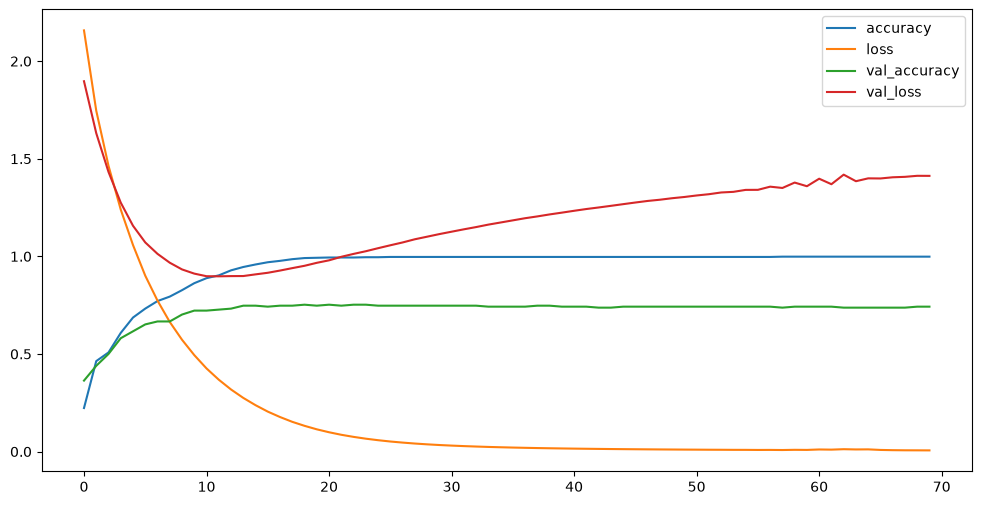

In [23]:
plotHistory(model_1_history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step
Accuracy : 0.79412 



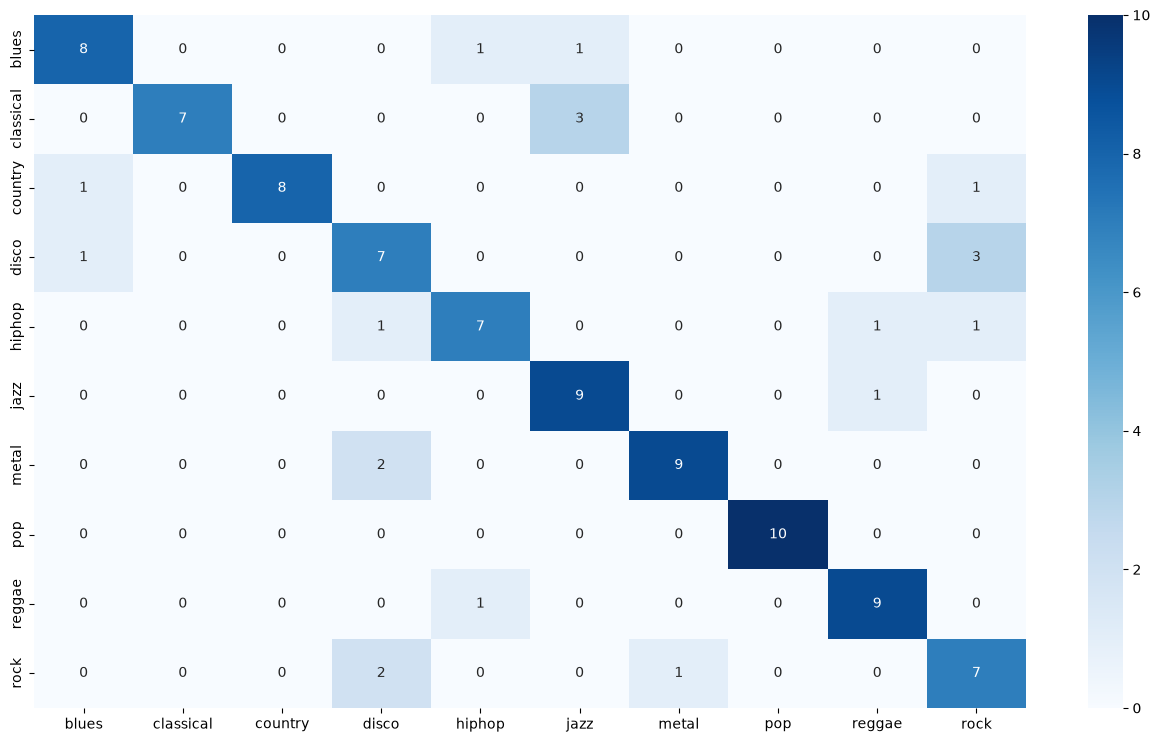

In [24]:
generateConfusionMatrix(model=model_1,filename="model1")

In [25]:
model_2 = k.models.Sequential([
    k.layers.Dense(512, activation='relu', input_shape=(X_train.shape[1],)),
    k.layers.Dropout(0.2),
    
    k.layers.Dense(256, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(128, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(64, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(10, activation='softmax'),
])
print(model_2.summary())
model_2_history = trainModel(model=model_2, epochs=100, optimizer='adam')

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_8 (Dense)                 │ (None, 512)            │        30,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,338 (794.29 KB)

 Trainable params: 203,338 (794.29 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step - accuracy: 0.1874 - loss: 2.2246WARNING:tensorflow:5 out of the last 561 calls to <function Trainer._make_function.<locals>.one_step_on_data at 0x0000022302BB68D0> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 177ms/step - accuracy: 0.1874 - loss: 2.2246 - val_accuracy: 0.3939 - val_loss: 1.9595
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.3505 - loss: 1.8994 - val_accurac

Max. Validation Accuracy 0.7777777910232544


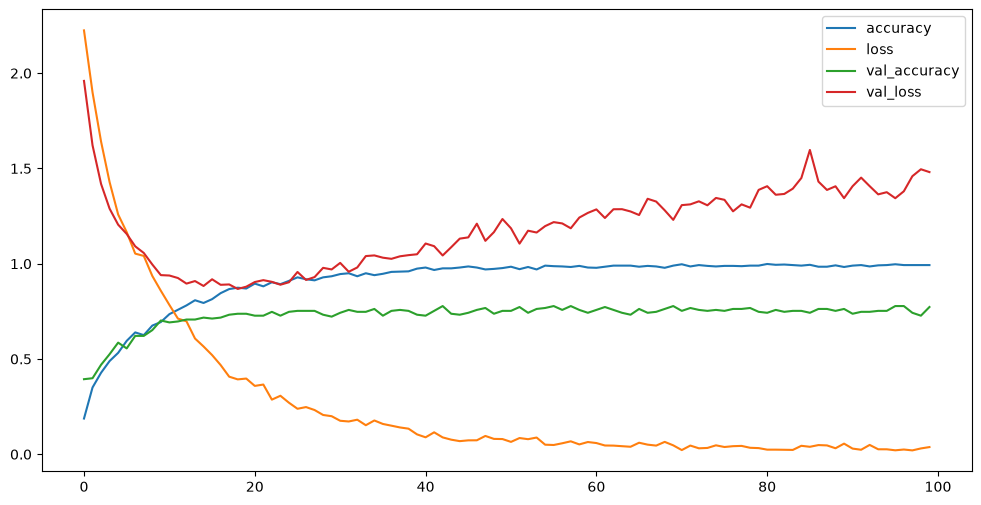

In [26]:
plotHistory(model_2_history)

1/4 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/stepWARNING:tensorflow:6 out of the last 12 calls to <function Trainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x00000223050F9B10> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Accuracy : 0.77451 



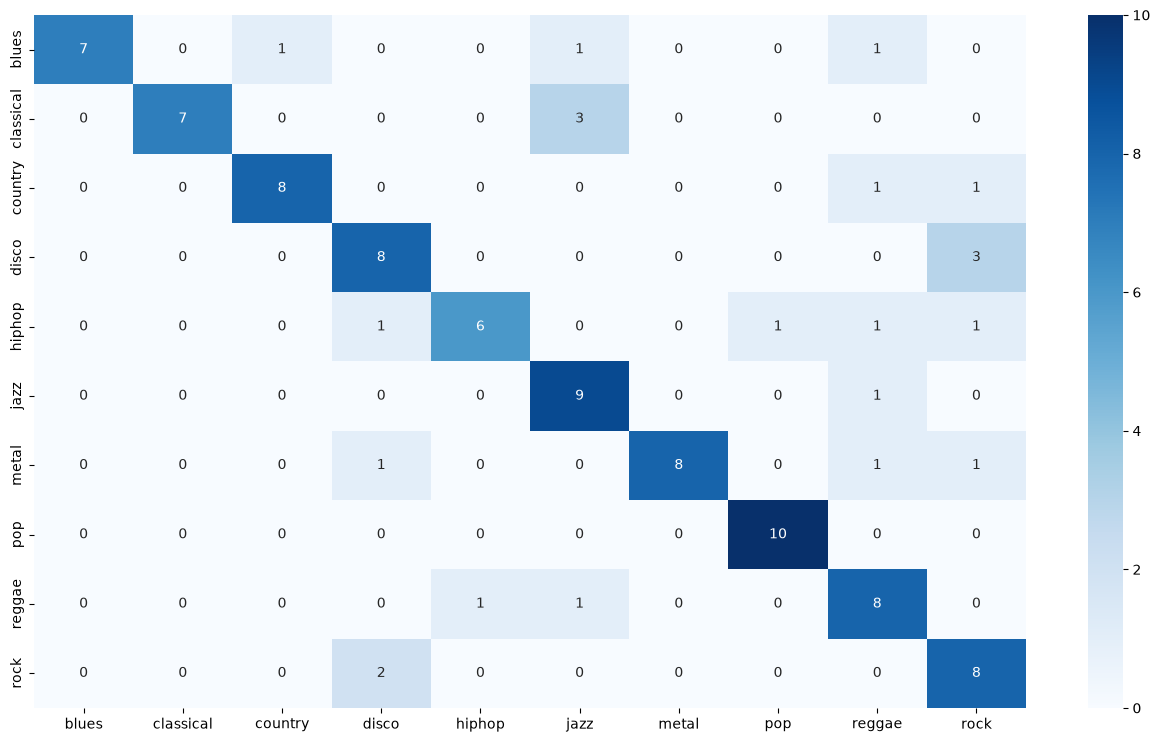

In [27]:
generateConfusionMatrix(model=model_2,filename="model2")

In [28]:
model_3 = k.models.Sequential([
    k.layers.Dense(512, activation='relu', input_shape=(X_train.shape[1],)),
    k.layers.Dropout(0.2),
    
    k.layers.Dense(256, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(128, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(64, activation='relu'),
    k.layers.Dropout(0.2),

    k.layers.Dense(10, activation='softmax'),
])
print(model_3.summary())
model_3_history = trainModel(model=model_3, epochs=700, optimizer='sgd')

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 512)            │        30,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 203,338 (794.29 KB)

 Trainable params: 203,338 (794.29 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 130ms/step - accuracy: 0.0959 - loss: 2.3608 - val_accuracy: 0.1162 - val_loss: 2.3174
Epoch 2/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1273 - loss: 2.3236 - val_accuracy: 0.1364 - val_loss: 2.3025
Epoch 3/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1130 - loss: 2.3159 - val_accuracy: 0.1414 - val_loss: 2.2889
Epoch 4/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1130 - loss: 2.3116 - val_accuracy: 0.1515 - val_loss: 2.2755
Epoch 5/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1502 - loss: 2.2744 - val_accuracy: 0.1768 - val_loss: 2.2628
Epoch 6/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1416 - loss: 2.2707 - val_accuracy: 0.2071 - val_loss: 2.2506
Epoch 7/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.1803 - loss: 2.2590 - val_accuracy: 0.2273 - val_loss: 2.2388
Epoch 8/700
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.1946 - loss: 2.2366 - val_accuracy: 0.2273 - val

Max. Validation Accuracy 0.7626262903213501


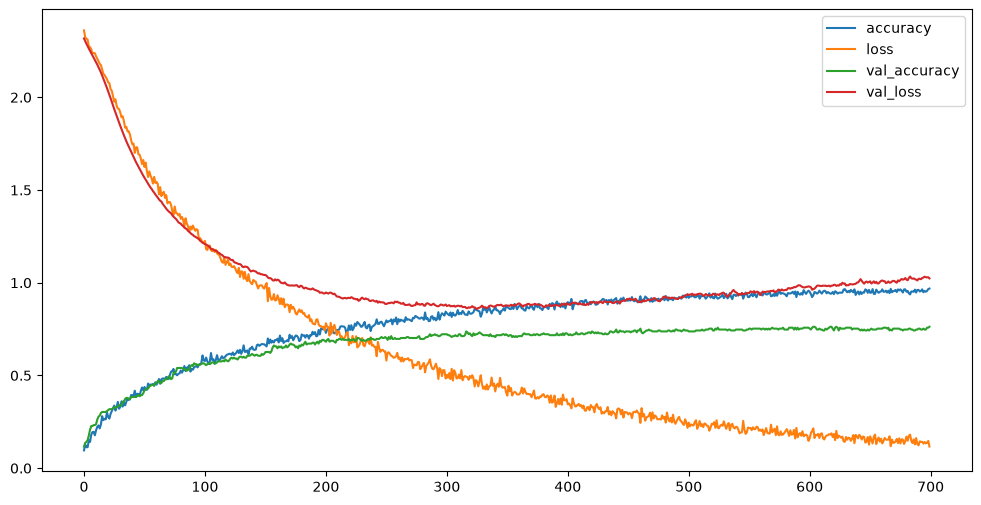

In [29]:
plotHistory(model_3_history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
Accuracy : 0.81373 



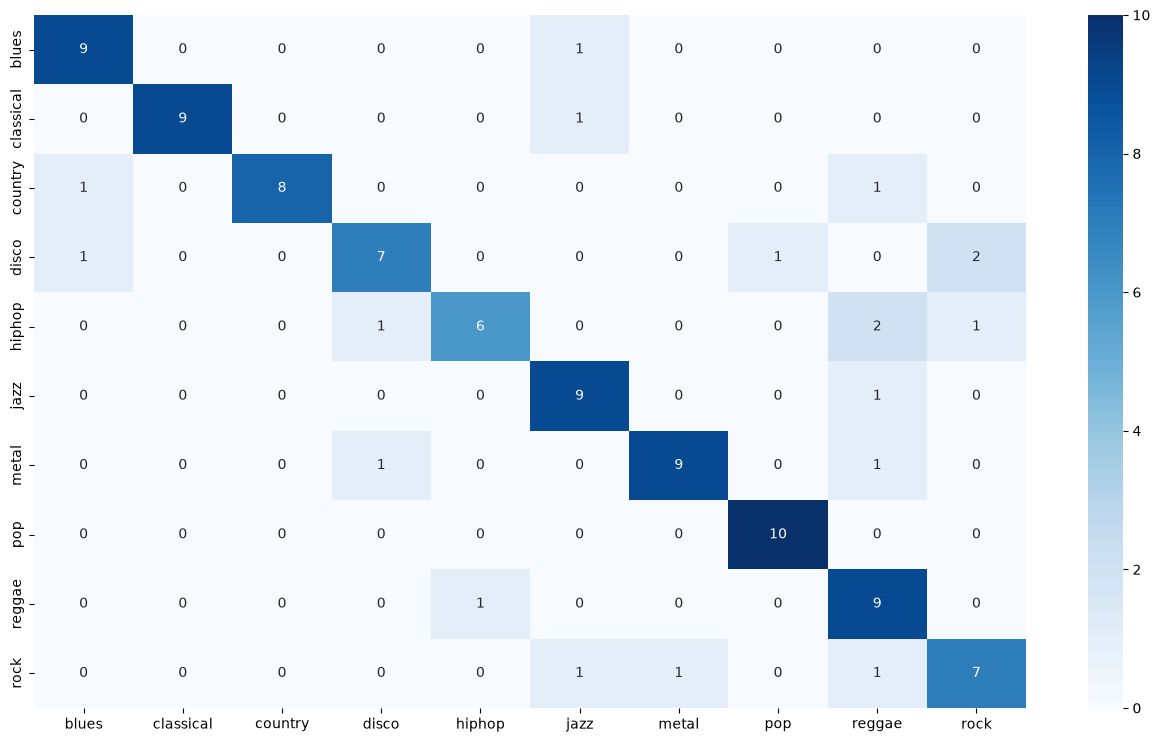

In [30]:
generateConfusionMatrix(model=model_3,filename="model3")

In [31]:
model_4 = k.models.Sequential([
    k.layers.Dense(1024, activation='relu', input_shape=(X_train.shape[1],)),
    k.layers.Dropout(0.3),
    
    k.layers.Dense(512, activation='relu'),
    k.layers.Dropout(0.3),

    k.layers.Dense(256, activation='relu'),
    k.layers.Dropout(0.3),

    k.layers.Dense(128, activation='relu'),
    k.layers.Dropout(0.3),

    k.layers.Dense(64, activation='relu'),
    k.layers.Dropout(0.3),

    k.layers.Dense(10, activation='softmax'),
])
print(model_4.summary())
model_4_history = trainModel(model=model_4, epochs=250, optimizer='adam')

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_18 (Dense)                │ (None, 1024)           │        60,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 512)            │       524,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_23 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 758,346 (2.89 MB)

 Trainable params: 758,346 (2.89 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/250
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 189ms/step - accuracy: 0.1402 - loss: 2.2805 - val_accuracy: 0.3081 - val_loss: 2.0882
Epoch 2/250
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.2675 - loss: 2.0453 - val_accuracy: 0.3283 - val_loss: 1.8098
Epoch 3/250
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.3104 - loss: 1.8680 - val_accuracy: 0.3586 - val_loss: 1.6096
Epoch 4/250
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3519 - loss: 1.7279 - val_accuracy: 0.4343 - val_loss: 1.5049
Epoch 5/250
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3920 - loss: 1.6594 - val_accuracy: 0.4495 - val_loss: 1.4356
Epoch 6/250
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4506 - loss: 1.5261 - val_accuracy: 0.4949 - val_loss: 1.3404
Epoch 7/250
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.4707 - loss: 1.4355 - val_accuracy: 0.5404 - val_loss: 1.2464
Epoch 8/250
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.5279 - loss: 1.3148 - val_accuracy: 0.5657 - val

Max. Validation Accuracy 0.7828282713890076


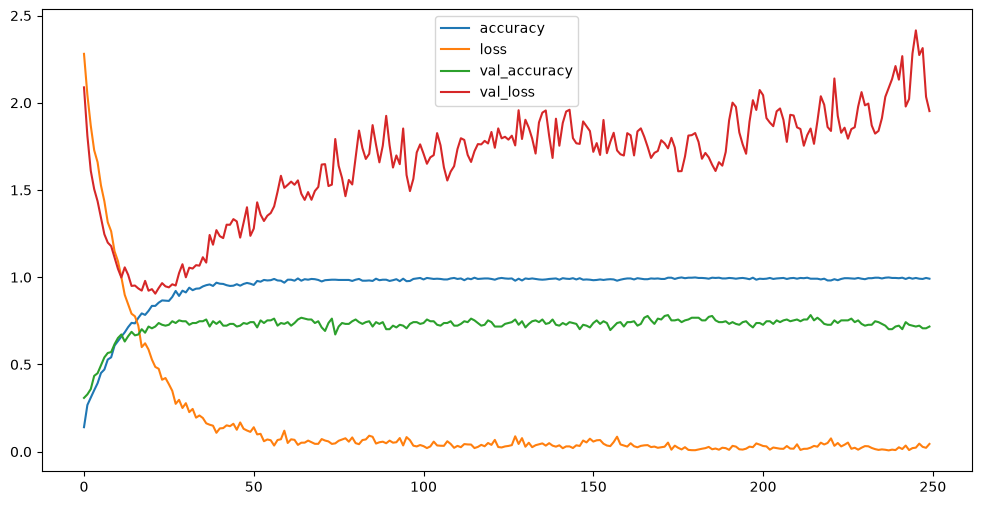

In [32]:
plotHistory(model_4_history)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
Accuracy : 0.76471 



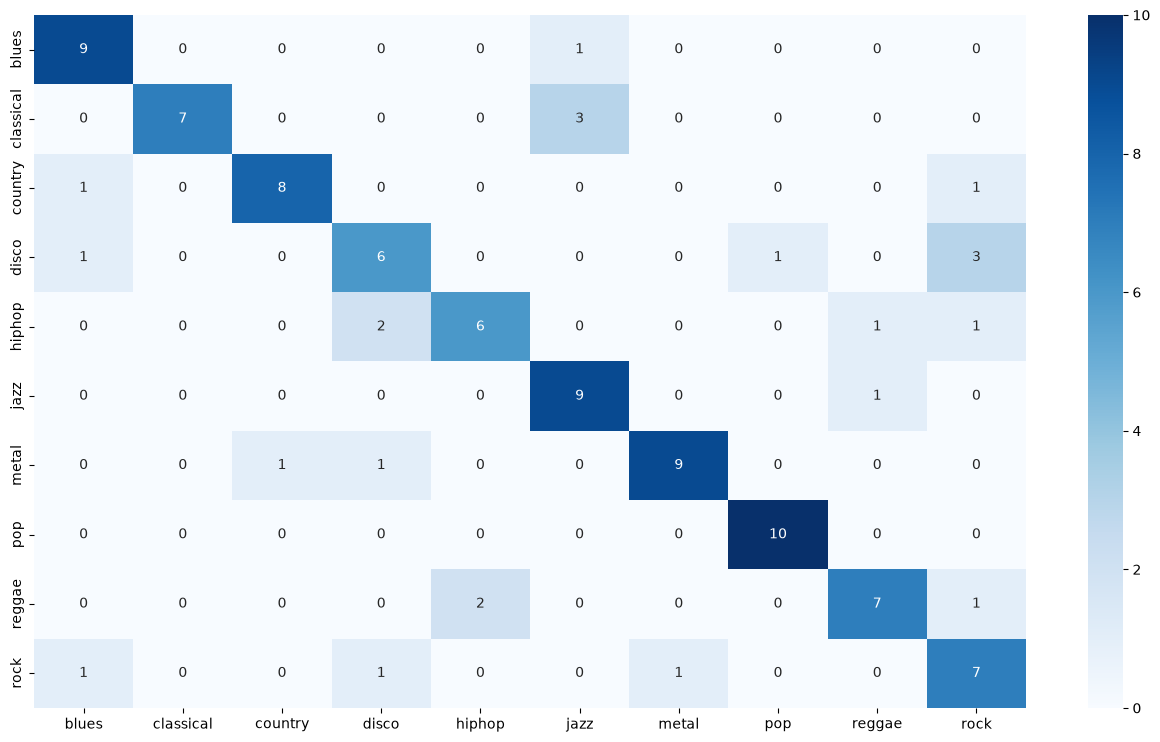

In [33]:
generateConfusionMatrix(model=model_4,filename="model4")

## Testing Models

In [34]:
def extractFeatures(file):
    path = file
    y, sr = librosa.load(path)  
    audio_file, _ = librosa.effects.trim(y)
    
    zero_crossing_rate = librosa.feature.zero_crossing_rate(audio_file, pad=False)
    mean_zero_crossing_rate = np.mean(zero_crossing_rate)
    var_zero_crossings_rate = np.var(zero_crossing_rate)
    
    chroma_stft = librosa.feature.chroma_stft(y=audio_file,sr=sr)
    mean_chroma_stft = np.mean(chroma_stft)
    var_chroma_stft = np.var(chroma_stft)
    
    rms = librosa.feature.rms(y=audio_file)
    mean_rms = np.mean(rms)
    var_rms = np.var(rms)
    
    spectral_centroid = librosa.feature.spectral_centroid(y=audio_file, sr=sr)
    mean_spectral_centroid = np.mean(spectral_centroid)
    var_spectral_centroid = np.var(spectral_centroid)
    
    spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio_file, sr=sr)
    mean_spectral_bandwidth = np.mean(spectral_bandwidth)
    var_spectral_bandwidth = np.var(spectral_bandwidth)
    
    spectral_rolloff = librosa.feature.spectral_rolloff(y=audio_file, sr=sr)
    mean_spectral_rolloff = np.mean(spectral_rolloff)
    var_spectral_rolloff = np.var(spectral_rolloff)
    
    harmonic, percussive = librosa.effects.hpss(audio_file)
    mean_harmonic = np.mean(harmonic)
    var_harmonic = np.var(harmonic)
    mean_percussive = np.mean(percussive)
    var_percussive = np.var(percussive)

    tempo = librosa.feature.tempo(y=audio_file, sr=sr)

    mfccs = librosa.feature.mfcc(y=audio_file, sr=sr)
    mfcc_means = np.mean(mfccs, axis=1)
    mfcc_vars = np.var(mfccs, axis=1)
    rows = []
    rows.append({
        'sample_rate': sr,
        'chroma_stft_mean': mean_chroma_stft,
        'chroma_stft_var': var_chroma_stft,
        'rms_mean': mean_rms,
        'rms_var': var_rms,
        'spectral_centroid_mean': mean_spectral_centroid,
        'spectral_centroid_var': var_spectral_centroid,
        'spectral_bandwidth_mean': mean_spectral_bandwidth,
        'spectral_bandwidth_var': var_spectral_bandwidth,
        'spectral_rolloff_mean': mean_spectral_rolloff,
        'spectral_rolloff_var': var_spectral_rolloff,
        'zero_crossing_rate_mean': mean_zero_crossing_rate,
        'zero_crossing_rate_var': var_zero_crossings_rate,
        'harmony_mean': mean_harmonic,
        'harmony_var': var_harmonic,
        'percussive_mean': mean_percussive,
        'percussive_var': var_percussive,
        'tempo': tempo[0],
        'mfcc1_mean':mfcc_means[0],
        'mfcc1_var':mfcc_vars[0],
        'mfcc2_mean':mfcc_means[1],
        'mfcc2_var':mfcc_vars[1],
        'mfcc3_mean':mfcc_means[2],
        'mfcc3_var':mfcc_vars[2],
        'mfcc4_mean':mfcc_means[3],
        'mfcc4_var':mfcc_vars[3],
        'mfcc5_mean':mfcc_means[4],
        'mfcc5_var':mfcc_vars[4],
        'mfcc6_mean':mfcc_means[5],
        'mfcc6_var':mfcc_vars[5],
        'mfcc7_mean':mfcc_means[6],
        'mfcc7_var':mfcc_vars[6],
        'mfcc8_mean':mfcc_means[7],
        'mfcc8_var':mfcc_vars[7],
        'mfcc9_mean':mfcc_means[8],
        'mfcc9_var':mfcc_vars[8],
        'mfcc10_mean':mfcc_means[9],
        'mfcc10_var':mfcc_vars[9],
        'mfcc11_mean':mfcc_means[10],
        'mfcc11_var':mfcc_vars[10],
        'mfcc12_mean':mfcc_means[11],
        'mfcc12_var':mfcc_vars[11],
        'mfcc13_mean':mfcc_means[12],
        'mfcc13_var':mfcc_vars[12],
        'mfcc14_mean':mfcc_means[13],
        'mfcc14_var':mfcc_vars[13],
        'mfcc15_mean':mfcc_means[14],
        'mfcc15_var':mfcc_vars[14],
        'mfcc16_mean':mfcc_means[15],
        'mfcc16_var':mfcc_vars[15],
        'mfcc17_mean':mfcc_means[16],
        'mfcc17_var':mfcc_vars[16],
        'mfcc18_mean':mfcc_means[17],
        'mfcc18_var':mfcc_vars[17],
        'mfcc19_mean':mfcc_means[18],
        'mfcc19_var':mfcc_vars[18],
        'mfcc20_mean':mfcc_means[19],
        'mfcc20_var':mfcc_vars[19],
    })
    to_return = pd.DataFrame(rows)
    to_return = pd.DataFrame(scaler.transform(to_return), columns=X_train.columns)
    return to_return

def testSample(model, file):
    predictions = model.predict(extractFeatures(file))
    predicted_class = np.argmax(predictions, axis=1)[0]
    predicted_genre = GTZAN_GENRES[predicted_class]
    confidence = predictions[0][predicted_class] * 100
    return predicted_genre, confidence

In [35]:
def displaySpectogram(filename):

    n_fft = 2048 # FFT window size
    hop_length = 512 # number audio of frames between STFT columns (looks like a good default)

    y, sr = librosa.load(filename)  
    audio_file, _ = librosa.effects.trim(y)

    plt.figure(figsize = (16, 6))

    #Fourier Transform
    D = np.abs(librosa.stft(audio_file, n_fft = n_fft, hop_length = hop_length))
    plt.plot(D);
    plt.title(f"{filename} STFT", fontsize = 23);

    #Spectogram
    DB = librosa.amplitude_to_db(D, ref = np.max)
    plt.figure(figsize = (16, 6))
    librosa.display.specshow(DB, sr = sr, hop_length = hop_length, x_axis = 'time', y_axis = 'log',
                        cmap = 'cool')
    plt.colorbar();
    plt.title(f"{filename} Spectrogram", fontsize = 23);

    #Mel Spectogram
    S = librosa.feature.melspectrogram(y=y, sr=sr)
    S_DB = librosa.amplitude_to_db(S, ref=np.max)
    plt.figure(figsize = (16, 6))
    librosa.display.specshow(S_DB, sr=sr, hop_length=hop_length, x_axis = 'time', y_axis = 'log',
                        cmap = 'cool');
    plt.colorbar();
    plt.title(f"{filename} Mel Spectrogram", fontsize = 23);

def normalize(x, axis=0):
    return sklearn.preprocessing.minmax_scale(x, axis=axis)

def displayFeatures(filename):
    y, sr = librosa.load(filename)  
    audio_file, _ = librosa.effects.trim(y)
    y_harm, y_perc = librosa.effects.hpss(audio_file)

    plt.figure(figsize = (16, 6))
    plt.plot(y_harm, color = '#A300F9');
    plt.plot(y_perc, color = '#FFB100');
    plt.title(f"{filename} Harmonics and Percussive", fontsize = 23);

    #Plotting the Spectral Centroid along the waveform
    spectral_centroids = librosa.feature.spectral_centroid(y=audio_file, sr=sr)[0]
    frames = range(len(spectral_centroids))
    t = librosa.frames_to_time(frames)

    plt.figure(figsize = (16, 6))
    librosa.display.waveshow(y=audio_file, sr=sr, alpha=0.4, color = '#A300F9');
    plt.plot(t, normalize(spectral_centroids), color='#FFB100');
    plt.title(f"{filename} Spectral Centroid", fontsize = 23);

    # Spectral Bandwidth Vector
    spectral_bandwidth = librosa.feature.spectral_bandwidth(y=audio_file, sr=sr)[0]

    plt.figure(figsize = (16, 6))
    librosa.display.waveshow(audio_file, sr=sr, alpha=0.4, color = '#A300F9');
    plt.plot(t, normalize(spectral_bandwidth), color='#FFB100');
    plt.title(f"{filename} Spectral Bandwidth", fontsize = 23);

    # Spectral RollOff Vector
    spectral_rolloff = librosa.feature.spectral_rolloff(y=audio_file, sr=sr)[0]

    plt.figure(figsize = (16, 6))
    librosa.display.waveshow(audio_file, sr=sr, alpha=0.4, color = '#A300F9');
    plt.plot(t, normalize(spectral_rolloff), color='#FFB100');
    plt.title(f"{filename} Spectral Roll Off", fontsize = 23);


    #MFCC
    mfccs = librosa.feature.mfcc(y=audio_file, sr=sr)
    mfccs = sklearn.preprocessing.scale(mfccs, axis=1)

    #Displaying  the MFCCs:
    plt.figure(figsize = (16, 6))
    librosa.display.specshow(mfccs, sr=sr, x_axis='time', cmap = 'cool');
    plt.title(f"{filename} MFCC", fontsize = 23);

    hop_length = 5000

    # Chromogram
    chromagram = librosa.feature.chroma_stft(y=audio_file, sr=sr, hop_length=hop_length)

    plt.figure(figsize=(16, 6))
    librosa.display.specshow(chromagram, x_axis='time', y_axis='chroma', hop_length=hop_length, cmap='coolwarm');
    plt.title(f"{filename} Chroma Frequencies", fontsize = 23);



In [36]:
input_file = 'orchestra.wav'

In [41]:
genre, confidence = testSample(model_1, input_file)

print("Predicted Genre:", genre)
print("Confidence:", f"{confidence:.5f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Predicted Genre: classical
Confidence: 95.78059%


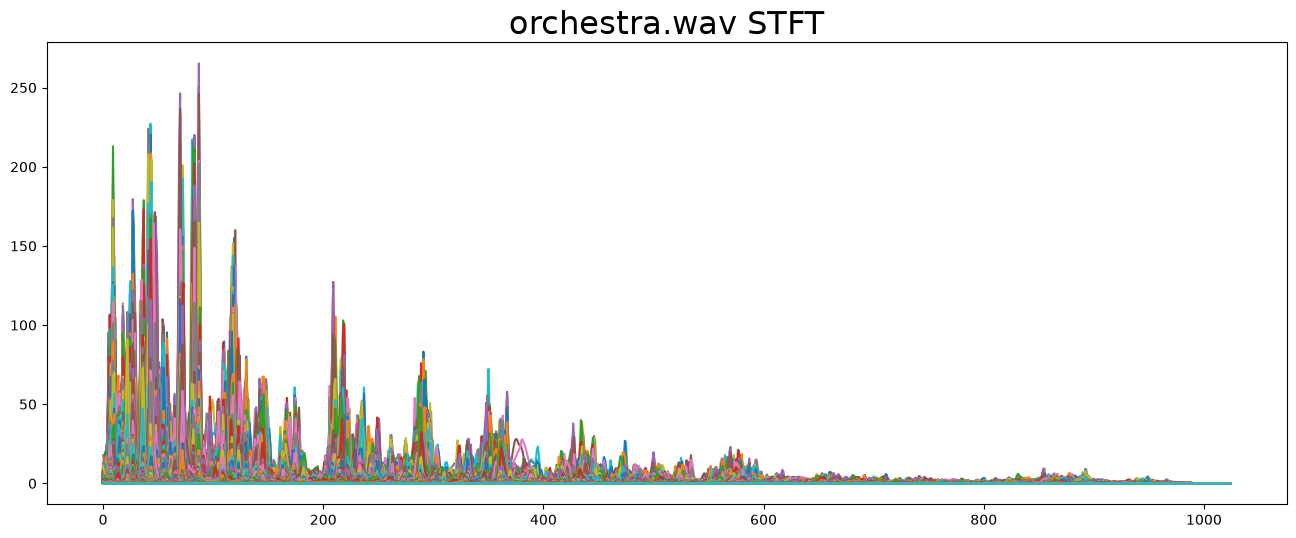

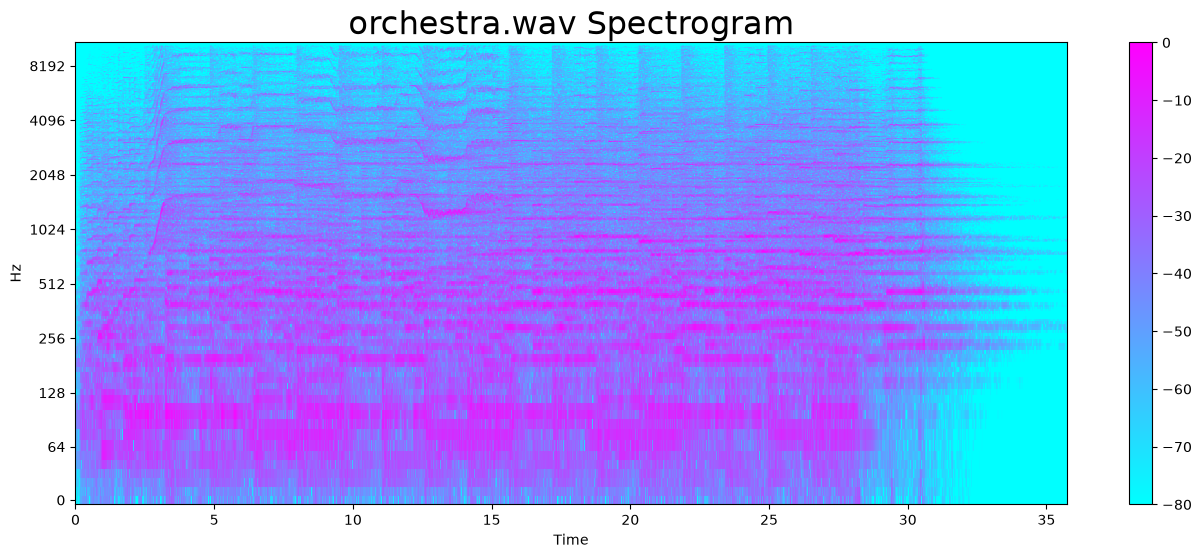

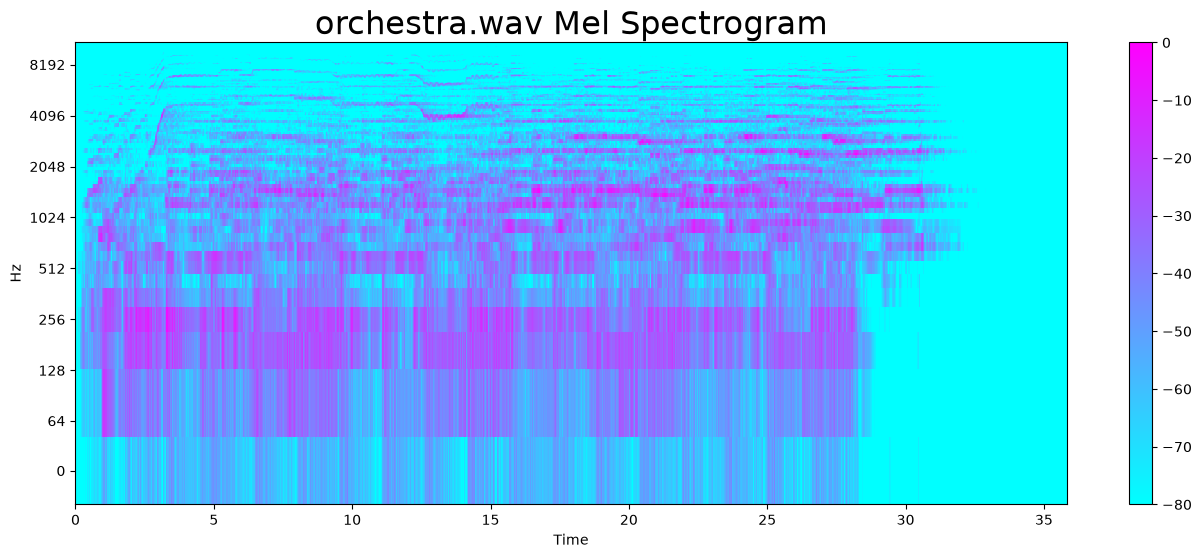

In [42]:
displaySpectogram(input_file)

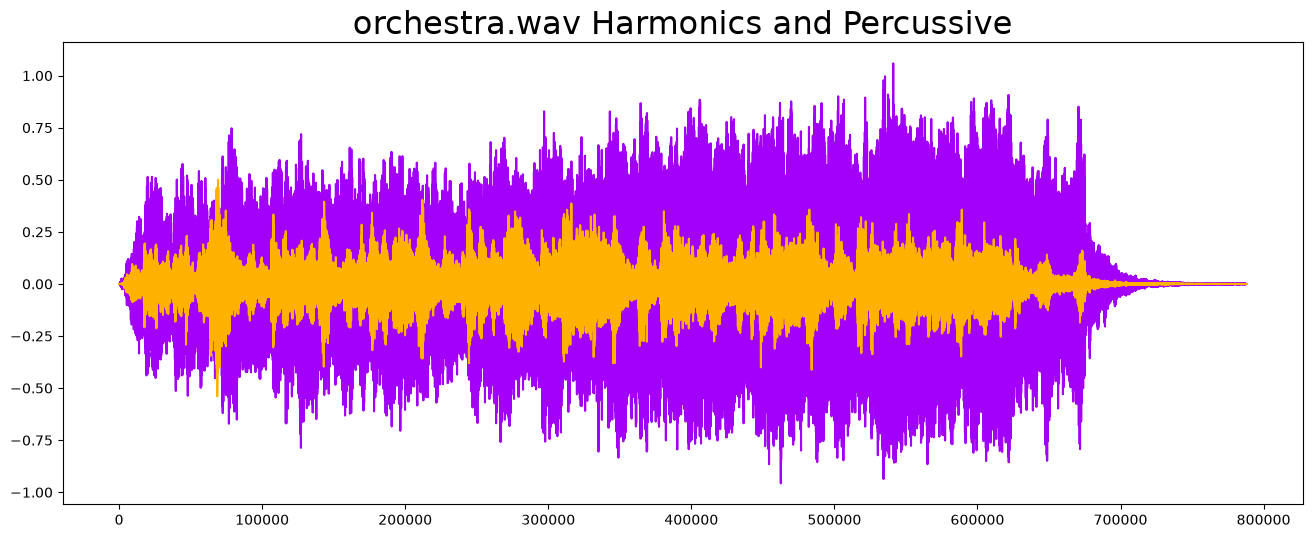

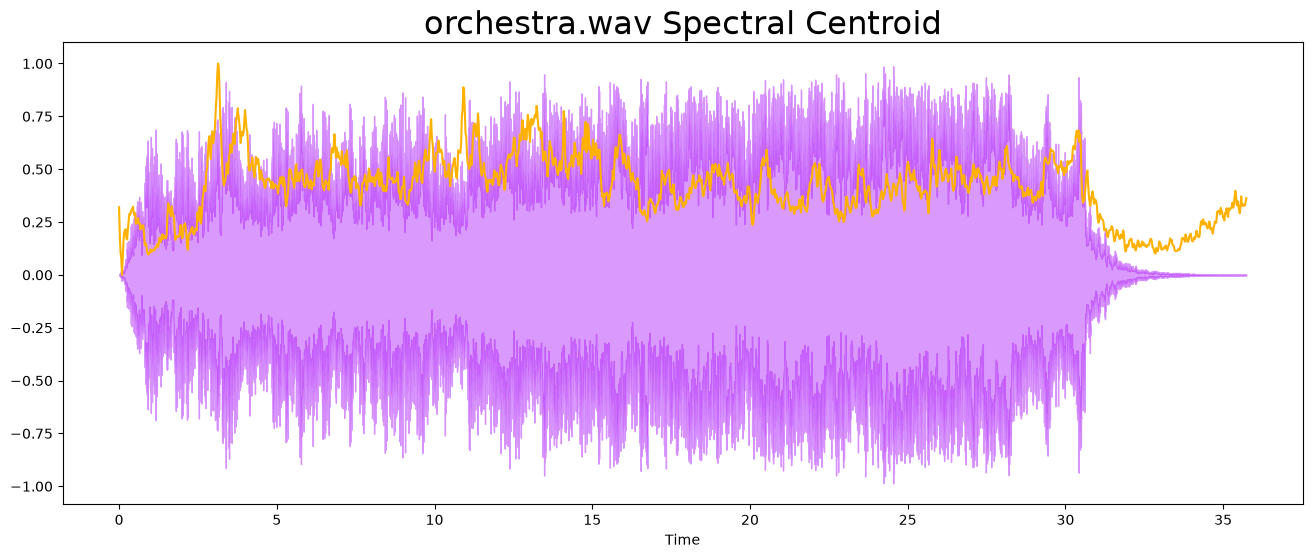

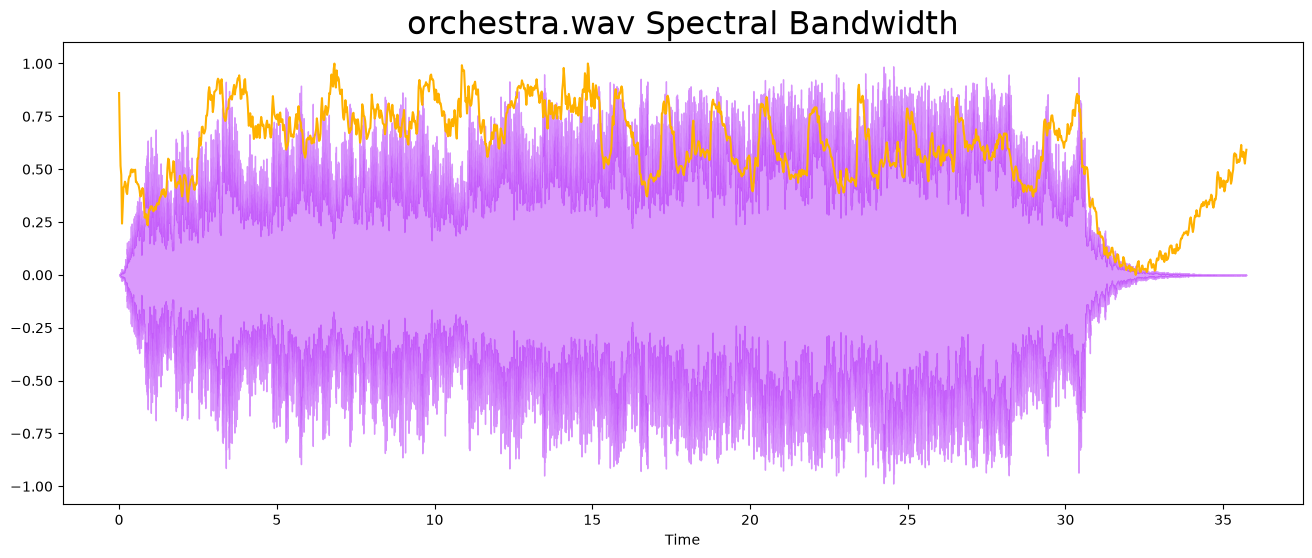

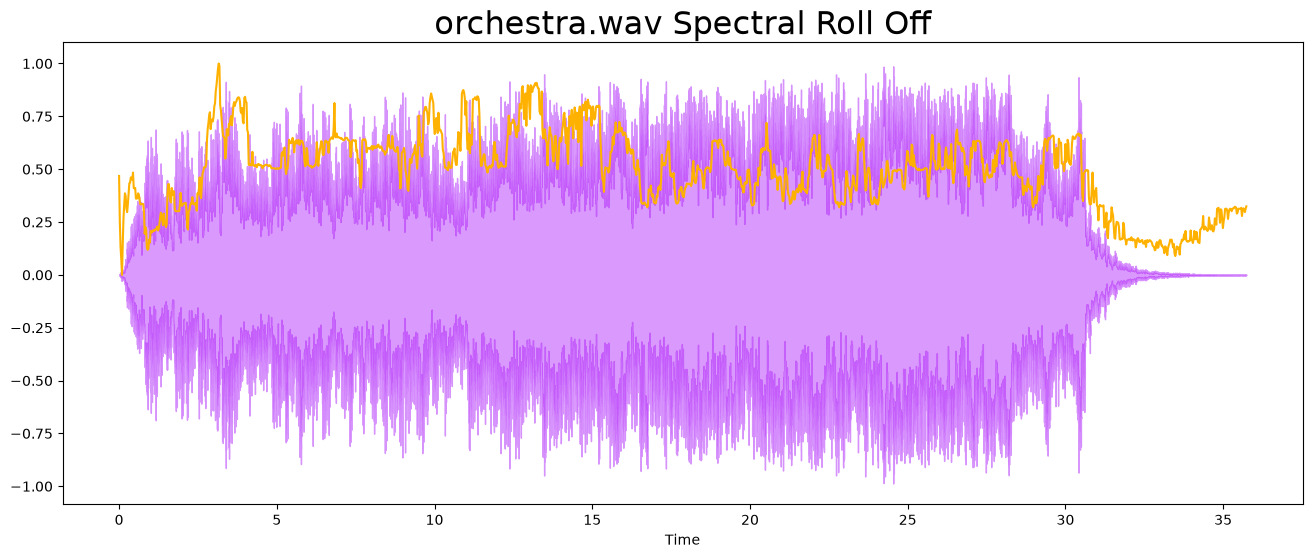

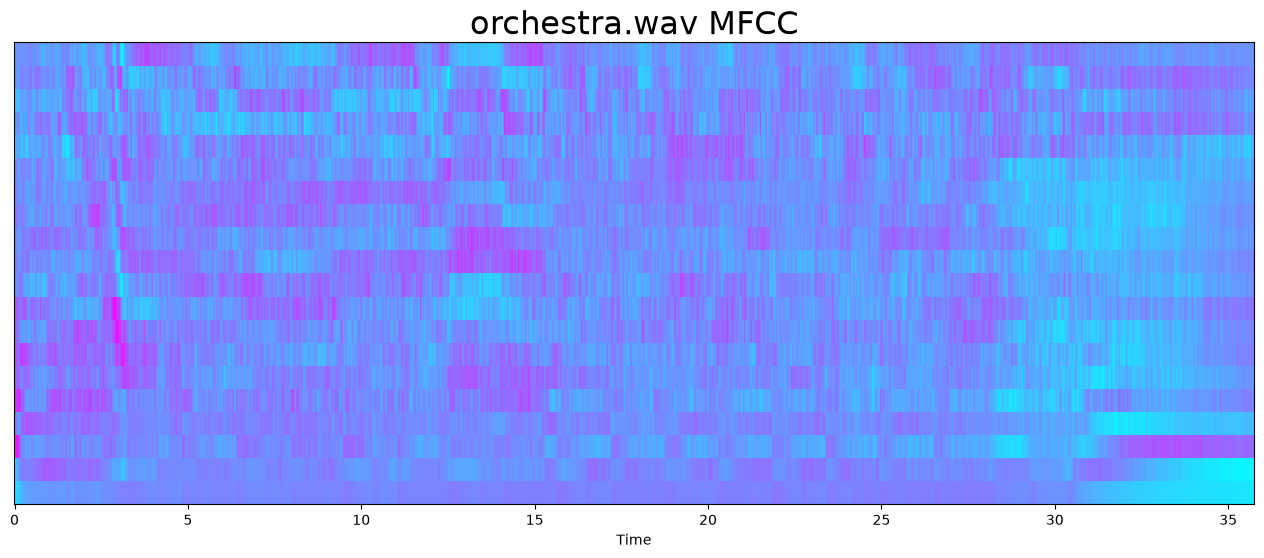

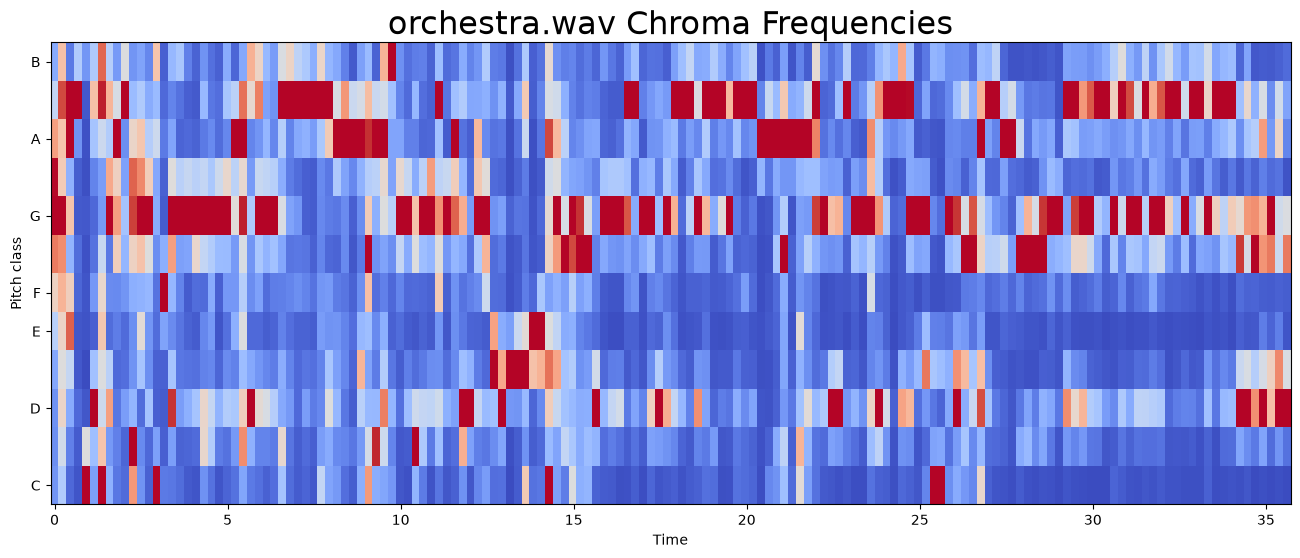

In [43]:
displayFeatures(input_file)

In [45]:
input_files = ['orchestra.wav']

for file in input_files:
    genre, confidence = testSample(model_3, file)
    print("Predicted Genre:", genre)
    print("Confidence:", f"{confidence:.5f}%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step
Predicted Genre: classical
Confidence: 96.88256%
